# Spatial Analysis and Evolution of the Housing Stock in Catalonia (1981–2021)

* **Author:** Adrià Benito Carayol
* **Project:** `Speculation-Map` — Big Data Analysis and Visualization (University of Barcelona)

### Notebook Objective
This notebook explores the historical evolution and territorial distribution of the family housing stock across Catalan municipalities between **1981 and 2021**. Specifically, it analyzes:
1. **Absolute spatial distribution:** Total number of dwellings per municipality and its decennial census evolution (static maps and animated GIFs).
2. **Residential pressure per capita:** Evolution of the dwellings-per-inhabitant ratio by merging census housing records with municipal population data.
3. **Housing stock structure and usage:** Evolution of the relative share between primary and non-primary dwellings (secondary residences or vacant units) across major territorial areas.
4. **Demographic scaling (2021):** Relationship between municipal population size and per-capita housing availability.

### Data Sources
* **Municipal boundaries:** Cartographic and Geological Institute of Catalonia (`CatalunyaMapMunicipalities.json`, ETRS89 / UTM zone 31N projection — `EPSG:25831`).
* **Housing census (1981–2021) and municipal population:** Statistical Institute of Catalonia (Idescat).

### AI Usage:

AI tools were used as a support in some parts of the creation of the figures (for example, to add scale bars to the maps).

## 1. Municipal Map of Total Dwellings (Single Census Year)
This first cell loads the municipal geographic layer and plots the total number of family dwellings for a selected census year (`any_obj = 2021`). A **logarithmic scale** (`LogNorm`) with fixed bounds across the entire 1981–2021 period is applied to facilitate visual comparison between densely populated cities and rural municipalities.

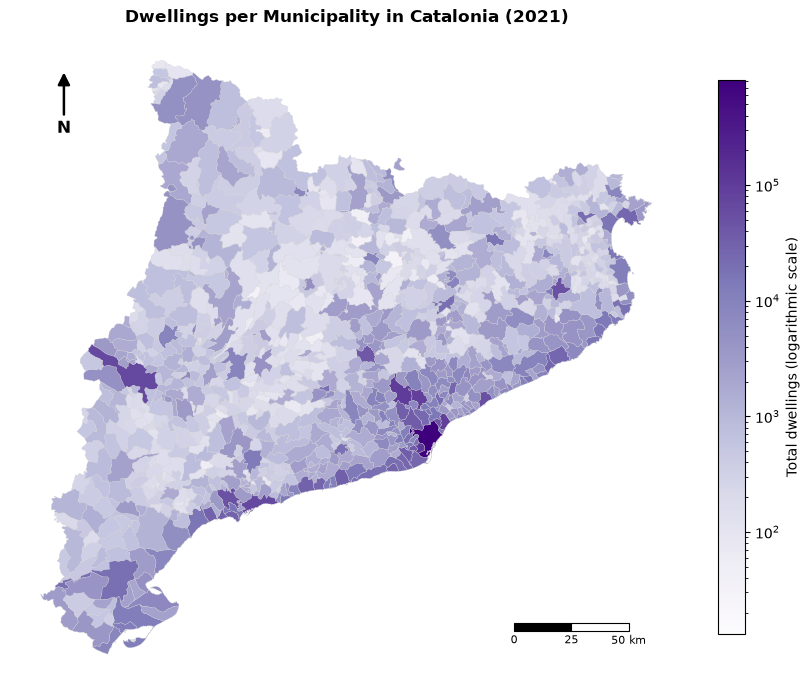

In [15]:
# Number of dwellings per municipality for a specific year

import geopandas as gpd
import matplotlib.colors as colors
import matplotlib.patches as mpatches  
import matplotlib.pyplot as plt
import pandas as pd

municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Load municipal geographic layer of Catalonia
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convert municipal code to 6-digit zero-padded string (e.g., '080193')

arxius_config = {                                          
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     # year: (filename, rows_to_skip, exact_total_column_name)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

any_obj = 2021   # Select the census year to visualize (1981, 1991, 2001, 2011, or 2021)
nom_arxiu, skip, col_total = arxius_config[any_obj]    # Extract filename, header rows to skip, and column name for that year
ruta_csv = f"../Data/BuildingsAvailable/{nom_arxiu}"

df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
df_hab = df_hab.dropna(subset=["Codi"]).copy()        # Remove rows without a municipal code
df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Strip whitespace and ensure 6-digit municipal codes
df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convert housing column to numeric (invalid strings become NaN)

gdf = municipis.merge(df_hab[["Codi", "Total"]], left_on="CODIMUNI", right_on="Codi", how="left")
gdf = gdf.to_crs(epsg=25831)  # Reproject coordinates to meters so North points straight up and the km scale bar is accurate

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")

gdf.plot(
    column="Total",
    cmap="Purples",
    norm=colors.LogNorm(vmin=13, vmax=811106),  # Logarithmic scale with fixed bounds (1981-2021) for cross-year comparison
    edgecolor="lightgrey",
    linewidth=0.2,
    legend=True,
    legend_kwds={"label": "Total dwellings (logarithmic scale)", "shrink": 0.7},
    missing_kwds={"color": "#e0e0e0", "hatch": "///", "label": "No data"},
    ax=ax,
)

# Add North arrow
ax.annotate(
    "N",
    xy=(0.08, 0.94),  # Arrow tip position
    xytext=(0.08, 0.85),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.8, mutation_scale=18),
)

# Add scale bar
xmin, ymin, xmax, ymax = gdf.total_bounds  # Get bounding box extents of Catalonia
longitud_total = 50_000  # Total length represented by the scale bar (50 km)
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.012
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.8))
ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.8))

for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
    ax.text(x_inici + offset, y_inici - alcada_barra * 0.6, etiqueta, ha="center", va="top", fontsize=8)

ax.set_title(f"Dwellings per Municipality in Catalonia ({any_obj})", fontweight="bold")
ax.set_axis_off()
plt.show()

## 2. Census Evolution of Total Dwellings (1981–2021)
We generate a horizontal row of **5 decennial census maps** (1981, 1991, 2001, 2011, and 2021) sharing a single color bar. This view highlights the expansion of the residential stock across the Barcelona metropolitan region and along the Catalan coastline.

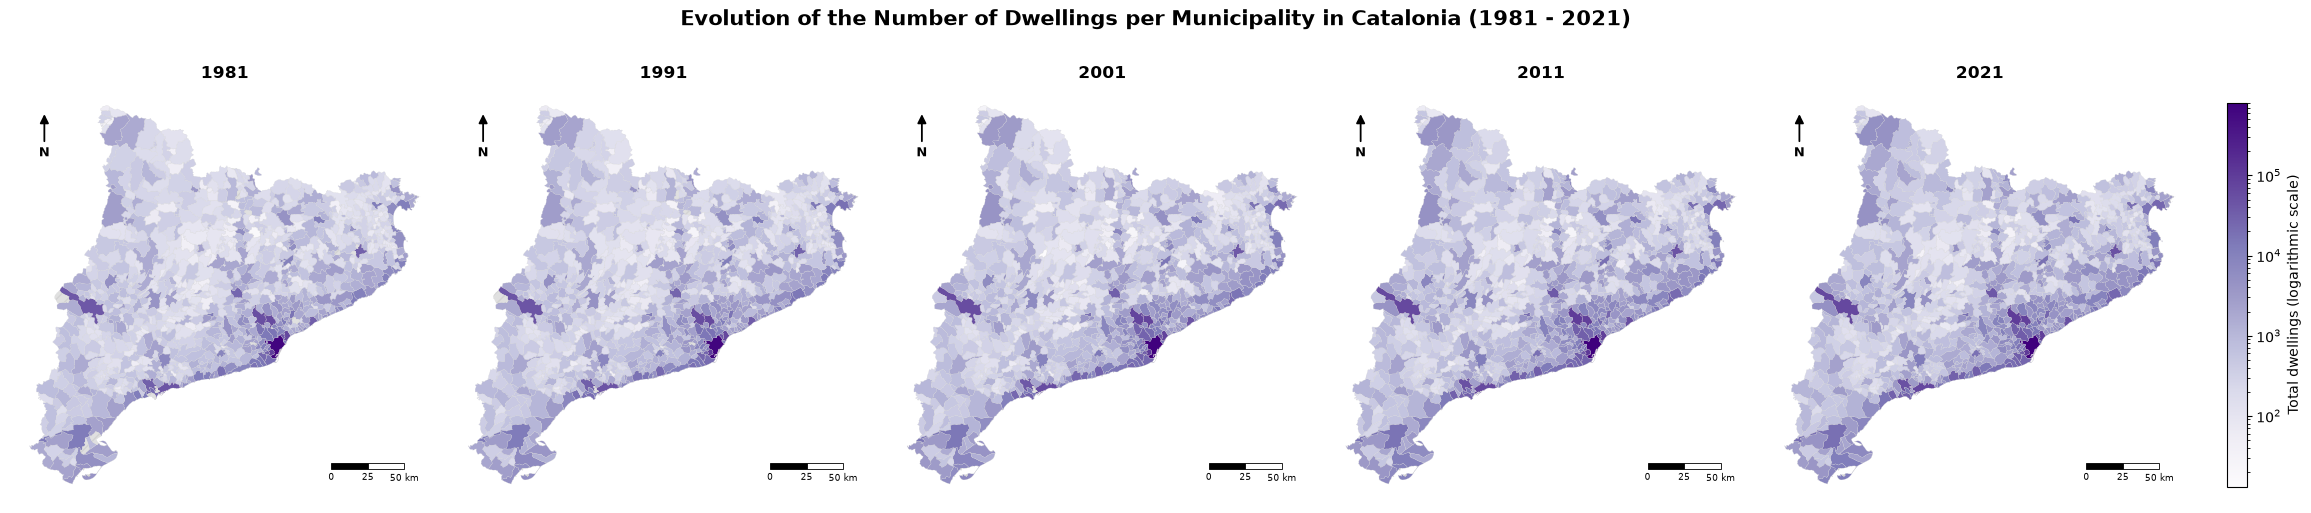

In [16]:
# Evolution of the number of dwellings per municipality (1981 - 2021) across 5 consecutive subplots

import geopandas as gpd
import matplotlib.cm as cm  
import matplotlib.colors as colors
import matplotlib.patches as mpatches 
import matplotlib.pyplot as plt
import pandas as pd

municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Load municipal geographic layer of Catalonia
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convert municipal code to 6-digit zero-padded string (e.g., '080193')
municipis = municipis.to_crs(epsg=25831)  # Reproject coordinates to meters so North points straight up and the km scale bar is accurate

arxius_config = {                                          
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     # year: (filename, rows_to_skip, exact_total_column_name)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

norm = colors.LogNorm(vmin=13, vmax=811106)  # Logarithmic scale with fixed bounds (1981-2021) for cross-year comparison
cmap = "Purples"  # Color palette

fig, axes = plt.subplots(1, 5, figsize=(23, 5.5), layout="constrained")  

xmin, ymin, xmax, ymax = municipis.total_bounds  # Get bounding box extents of Catalonia
longitud_total = 50_000  # Total length represented by the scale bar (50 km)
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.015
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

# Iterate through each subplot (ax) along with its year and file configuration
for ax, (any_obj, (nom_arxiu, skip, col_total)) in zip(axes, arxius_config.items()):
    ruta_csv = f"../Data/BuildingsAvailable/{nom_arxiu}"

    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()        # Remove rows without a municipal code
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Strip whitespace and ensure 6-digit municipal codes
    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convert housing column to numeric (invalid strings become NaN)

    gdf = municipis.merge(df_hab[["Codi", "Total"]], left_on="CODIMUNI", right_on="Codi", how="left")

    gdf.plot(
        column="Total",
        cmap=cmap,
        norm=norm,
        edgecolor="lightgrey",
        linewidth=0.15,
        legend=False,  # Disable individual legends to avoid repeating them 5 times
        missing_kwds={"color": "#e0e0e0", "hatch": "///"},
        ax=ax,
    )

    # Add North arrow
    ax.annotate(
        "N",
        xy=(0.08, 0.94),  # Arrow tip position
        xytext=(0.08, 0.84),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.3, mutation_scale=13),
    )

    # Add scale bar
    ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.6))
    ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.6))

    for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
        ax.text(x_inici + offset, y_inici - alcada_barra * 0.7, etiqueta, ha="center", va="top", fontsize=6.5)

    ax.set_title(f"{any_obj}", fontweight="bold", fontsize=12)  # Set the census year as each subplot's title
    ax.set_axis_off()

# Single shared color bar on the right for all subplots
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes, shrink=0.75, pad=0.015)
cbar.set_label("Total dwellings (logarithmic scale)", fontsize=10)

fig.suptitle("Evolution of the Number of Dwellings per Municipality in Catalonia (1981 - 2021)", fontweight="bold", fontsize=15)  # Main figure title
plt.show()

## 3. Animated GIF of Total Dwellings Evolution (1981–2021)


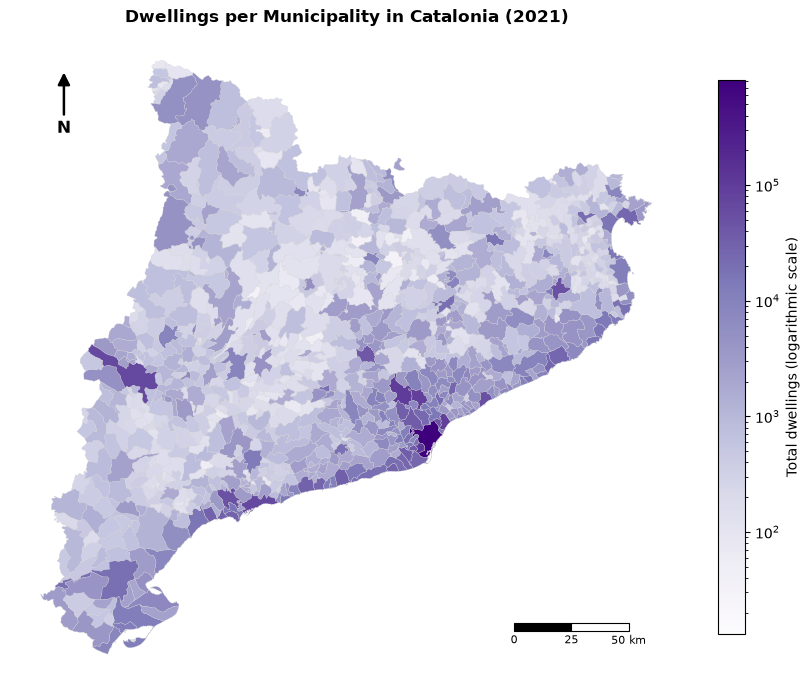

In [17]:
# Temporal evolution of the number of dwellings per municipality in Catalonia (1981 - 2021) as a GIF

import geopandas as gpd
import matplotlib.animation as animation  
import matplotlib.colors as colors
import matplotlib.patches as mpatches 
import matplotlib.pyplot as plt
import pandas as pd

municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Load municipal geographic layer of Catalonia
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convert municipal code to 6-digit zero-padded string (e.g., '080193')
municipis = municipis.to_crs(epsg=25831)  # Reproject coordinates to meters so North points straight up and the km scale bar is accurate

arxius_config = {                                          
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     # year: (filename, rows_to_skip, exact_total_column_name)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

anys = list(arxius_config.keys())  # Ordered list of the 5 census years
dades_per_any = {}  # Dictionary to store merged GeoDataFrames for each year

# Read and prepare data for all years before generating the animation
for any_obj, (nom_arxiu, skip, col_total) in arxius_config.items():
    ruta_csv = f"../Data/BuildingsAvailable/{nom_arxiu}"

    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()        # Remove rows without a municipal code
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Strip whitespace and ensure 6-digit municipal codes
    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convert housing column to numeric (invalid strings become NaN)

    dades_per_any[any_obj] = municipis.merge(df_hab[["Codi", "Total"]], left_on="CODIMUNI", right_on="Codi", how="left")

norm = colors.LogNorm(vmin=13, vmax=811106)  # Logarithmic scale with fixed bounds (1981-2021) for cross-year comparison
cmap = "Purples"  # Color palette

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")

# Draw an initial base map to generate the color bar once
dades_per_any[anys[0]].plot(
    column="Total",
    cmap=cmap,
    norm=norm,
    legend=True,
    legend_kwds={"label": "Total dwellings (logarithmic scale)", "shrink": 0.7},
    ax=ax,
)

xmin, ymin, xmax, ymax = municipis.total_bounds  # Get bounding box extents of Catalonia
longitud_total = 50_000  # Total length represented by the scale bar (50 km)
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.012
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

# Function that redraws the map for each frame of the animation
def actualitzar_fotograma(any_obj):
    ax.clear()  # Clear previous map without removing the color bar

    gdf = dades_per_any[any_obj]
    gdf.plot(
        column="Total",
        cmap=cmap,
        norm=norm,
        edgecolor="lightgrey",
        linewidth=0.2,
        legend=False,  # Color bar was already created outside the function
        missing_kwds={"color": "#e0e0e0", "hatch": "///"},
        ax=ax,
    )

    # Add North arrow
    ax.annotate(
        "N",
        xy=(0.08, 0.94),  # Arrow tip position
        xytext=(0.08, 0.85),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.8, mutation_scale=18),
    )

    # Add scale bar
    ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.8))
    ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.8))

    for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
        ax.text(x_inici + offset, y_inici - alcada_barra * 0.6, etiqueta, ha="center", va="top", fontsize=8)

    ax.set_title(f"Dwellings per Municipality in Catalonia ({any_obj})", fontweight="bold")
    ax.set_axis_off()

# Create animation (interval=1500 ms -> 1.5 seconds per year)
ani = animation.FuncAnimation(fig, actualitzar_fotograma, frames=anys, interval=1500, repeat=True)
ruta_gif = "../evolucio_habitatges_1981_2021.gif"
ani.save(ruta_gif, writer=animation.PillowWriter(fps=1/1.5), dpi=200)

plt.show()

## 4. Evolution of the Dwellings-per-Inhabitant Ratio (1981–2021)
To control for municipal population size, we merge the housing stock with historical population records (`poblacio_codis.xlsx`) and compute the **dwellings-per-inhabitant ratio** ($\text{Dwellings} / \text{Population}$). High values (above 1.0 dwelling per resident) highlight municipalities with strong tourist specialization or high concentrations of second homes.

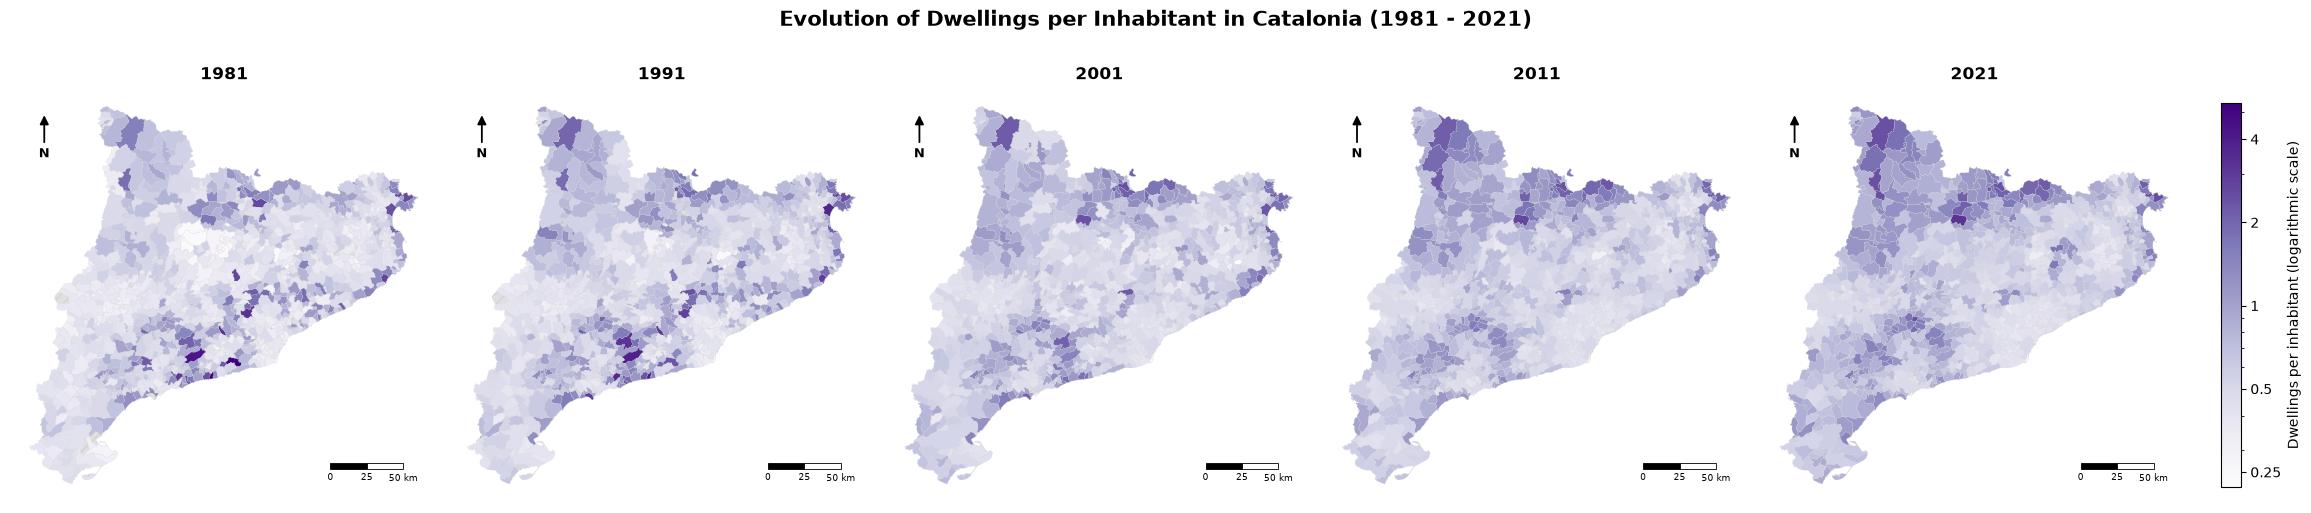

In [18]:
# Evolution of the dwellings-per-inhabitant ratio per municipality in Catalonia (1981 - 2021)

import geopandas as gpd
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Load municipal geographic layer of Catalonia
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convert municipal code to 6-digit zero-padded string (e.g., '080193')
municipis = municipis.to_crs(epsg=25831)  # Reproject coordinates to meters so North points straight up and the km scale bar is accurate

# Load and clean population data ('Dades' sheet from poblacio_codis.xlsx)
ruta_pob = "../Data/BuildingsAvailable/poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str})  # Read 'Dades' sheet forcing 1st column as string to keep leading zeros
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})  # Rename first two columns
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)  # Forward-fill municipal code and ensure 6 digits
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()  # Keep only valid 6-digit numeric codes (drops 'TOTAL' and footer notes)
df_pob["Any"] = df_pob["Any"].astype(int)  # Convert year to integer
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")  # Convert total population to numeric

arxius_config = {
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     # year: (filename, rows_to_skip, exact_total_column_name)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

norm = colors.LogNorm(vmin=0.22, vmax=5.4)  # Logarithmic scale with fixed bounds (1981-2021) for the dwellings/inhabitant ratio
cmap = "Purples"  # Color palette

fig, axes = plt.subplots(1, 5, figsize=(23, 5.5), layout="constrained")

xmin, ymin, xmax, ymax = municipis.total_bounds  # Get bounding box extents of Catalonia
longitud_total = 50_000  # Total length represented by the scale bar (50 km)
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.015
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

# Iterate through each subplot (ax) along with its year and file configuration
for ax, (any_obj, (nom_arxiu, skip, col_total)) in zip(axes, arxius_config.items()):
    ruta_csv = f"../Data/BuildingsAvailable/{nom_arxiu}"

    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()        # Remove rows without a municipal code
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Strip whitespace and ensure 6-digit municipal codes
    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convert housing column to numeric (invalid strings become NaN)

    # Filter population for the current year, merge with dwellings, and compute ratio
    df_pob_any = df_pob[df_pob["Any"] == any_obj][["Codi", "Poblacio"]]
    df_combinat = df_hab[["Codi", "Total"]].merge(df_pob_any, on="Codi", how="inner")
    df_combinat["Hab_per_hab"] = df_combinat["Total"] / df_combinat["Poblacio"]

    gdf = municipis.merge(df_combinat[["Codi", "Hab_per_hab"]], left_on="CODIMUNI", right_on="Codi", how="left")

    gdf.plot(
        column="Hab_per_hab",
        cmap=cmap,
        norm=norm,
        edgecolor="lightgrey",
        linewidth=0.15,
        legend=False,  # Disable individual legends to avoid repeating them 5 times
        missing_kwds={"color": "#e0e0e0", "hatch": "///"},
        ax=ax,
    )

    # Add North arrow
    ax.annotate(
        "N",
        xy=(0.08, 0.94),  # Arrow tip position
        xytext=(0.08, 0.84),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.3, mutation_scale=13),
    )

    # Add scale bar
    ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.6))
    ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.6))

    for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
        ax.text(x_inici + offset, y_inici - alcada_barra * 0.7, etiqueta, ha="center", va="top", fontsize=6.5)

    ax.set_title(f"{any_obj}", fontweight="bold", fontsize=12)  # Set the census year as each subplot's title
    ax.set_axis_off()

# Single shared color bar on the right for all subplots
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=axes, shrink=0.75, pad=0.015)

# Color bar tick values
cbar.set_ticks([0.25, 0.5, 1, 2, 4])
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:g}"))
cbar.ax.yaxis.set_minor_formatter(ticker.NullFormatter())

cbar.set_label("Dwellings per inhabitant (logarithmic scale)", fontsize=10)

fig.suptitle("Evolution of Dwellings per Inhabitant in Catalonia (1981 - 2021)", fontweight="bold", fontsize=15)  # Main figure title
plt.show()

## 5. Animated GIF of the Dwellings-per-Inhabitant Ratio (1981–2021)
We generate the animated version of the dwellings-per-inhabitant ratio evolution (`../evolucio_habitatges_per_habitant_1981_2021.gif`) keeping a fixed logarithmic color scale across all frames.

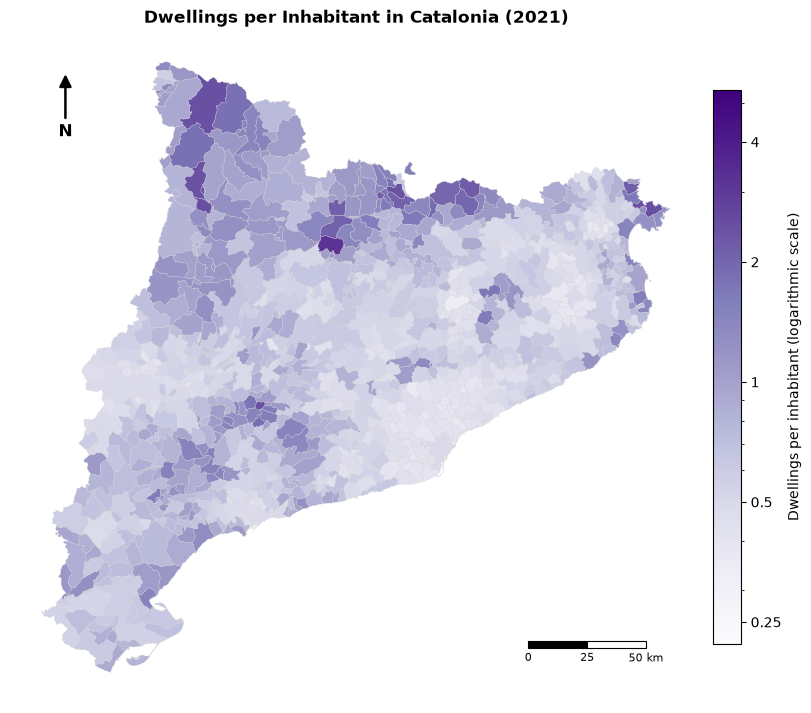

In [19]:
# Temporal evolution of the dwellings-per-inhabitant ratio per municipality in Catalonia (1981 - 2021) as a GIF

import geopandas as gpd
import matplotlib.animation as animation
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Load municipal geographic layer of Catalonia
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convert municipal code to 6-digit zero-padded string (e.g., '080193')
municipis = municipis.to_crs(epsg=25831)  # Reproject coordinates to meters so North points straight up and the km scale bar is accurate

# Load and clean population data ('Dades' sheet from poblacio_codis.xlsx)
ruta_pob = "../Data/BuildingsAvailable/poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str})  # Read 'Dades' sheet forcing 1st column as string to keep leading zeros
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})  # Rename first two columns
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)  # Forward-fill municipal code and ensure 6 digits
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()  # Keep only valid 6-digit numeric codes (drops 'TOTAL' and footer notes)
df_pob["Any"] = df_pob["Any"].astype(int)  # Convert year to integer
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")  # Convert total population to numeric

arxius_config = {
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),     # year: (filename, rows_to_skip, exact_total_column_name)
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

anys = list(arxius_config.keys())  # Ordered list of the 5 census years
dades_per_any = {}  # Dictionary to store merged GeoDataFrames for each year

# Read and prepare data for all years before generating the animation
for any_obj, (nom_arxiu, skip, col_total) in arxius_config.items():
    ruta_csv = f"../Data/BuildingsAvailable/{nom_arxiu}"

    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()        # Remove rows without a municipal code
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Strip whitespace and ensure 6-digit municipal codes
    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")   # Convert housing column to numeric (invalid strings become NaN)

    # Filter population for the current year, merge with dwellings, and compute ratio
    df_pob_any = df_pob[df_pob["Any"] == any_obj][["Codi", "Poblacio"]]
    df_combinat = df_hab[["Codi", "Total"]].merge(df_pob_any, on="Codi", how="inner")
    df_combinat["Hab_per_hab"] = df_combinat["Total"] / df_combinat["Poblacio"]

    dades_per_any[any_obj] = municipis.merge(df_combinat[["Codi", "Hab_per_hab"]], left_on="CODIMUNI", right_on="Codi", how="left")

norm = colors.LogNorm(vmin=0.22, vmax=5.4)  # Logarithmic scale with fixed bounds (1981-2021) for the dwellings/inhabitant ratio
cmap = "Purples"  # Color palette

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")

# Single color bar created once outside the animation
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.015)

# Color bar tick values
cbar.set_ticks([0.25, 0.5, 1, 2, 4])
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:g}"))
cbar.ax.yaxis.set_minor_formatter(ticker.NullFormatter())
cbar.set_label("Dwellings per inhabitant (logarithmic scale)", fontsize=10)

xmin, ymin, xmax, ymax = municipis.total_bounds  # Get bounding box extents of Catalonia
longitud_total = 50_000  # Total length represented by the scale bar (50 km)
tram = longitud_total / 2
alcada_barra = (ymax - ymin) * 0.012
x_inici = xmax - longitud_total - (xmax - xmin) * 0.04
y_inici = ymin + (ymax - ymin) * 0.04

# Function that redraws the map for each frame of the animation
def actualitzar_fotograma(any_obj):
    ax.clear()  # Clear previous map without removing the color bar

    gdf = dades_per_any[any_obj]
    gdf.plot(
        column="Hab_per_hab",
        cmap=cmap,
        norm=norm,
        edgecolor="lightgrey",
        linewidth=0.2,
        legend=False,  # Color bar was already created outside the function
        missing_kwds={"color": "#e0e0e0", "hatch": "///"},
        ax=ax,
    )

    # Add North arrow
    ax.annotate(
        "N",
        xy=(0.08, 0.94),  # Arrow tip position
        xytext=(0.08, 0.85),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(arrowstyle="-|>", facecolor="black", edgecolor="black", lw=1.8, mutation_scale=18),
    )

    # Add scale bar
    ax.add_patch(mpatches.Rectangle((x_inici, y_inici), tram, alcada_barra, facecolor="black", edgecolor="black", lw=0.8))
    ax.add_patch(mpatches.Rectangle((x_inici + tram, y_inici), tram, alcada_barra, facecolor="white", edgecolor="black", lw=0.8))

    for offset, etiqueta in [(0, "0"), (tram, "25"), (longitud_total, "50 km")]:
        ax.text(x_inici + offset, y_inici - alcada_barra * 0.6, etiqueta, ha="center", va="top", fontsize=8)

    ax.set_title(f"Dwellings per Inhabitant in Catalonia ({any_obj})", fontweight="bold")
    ax.set_axis_off()

# Create animation (interval=1500 ms -> 1.5 seconds per year)
ani = animation.FuncAnimation(fig, actualitzar_fotograma, frames=anys, interval=1500, repeat=True)
ruta_gif = "../evolucio_habitatges_per_habitant_1981_2021.gif"
ani.save(ruta_gif, writer=animation.PillowWriter(fps=1/1.5), dpi=200)

plt.show()

## 6. Housing Stock Composition by Territorial Area (1981–2021)
We group municipalities according to their county code (`CODICOMAR`) into four major geographic regions (**Metropolitan Area**, **Coast**, **Pyrenees & Pre-Pyrenees**, and **Inland Catalonia**) to compare how the share of **primary dwellings** versus **non-primary dwellings** (second homes and vacant units) has evolved.

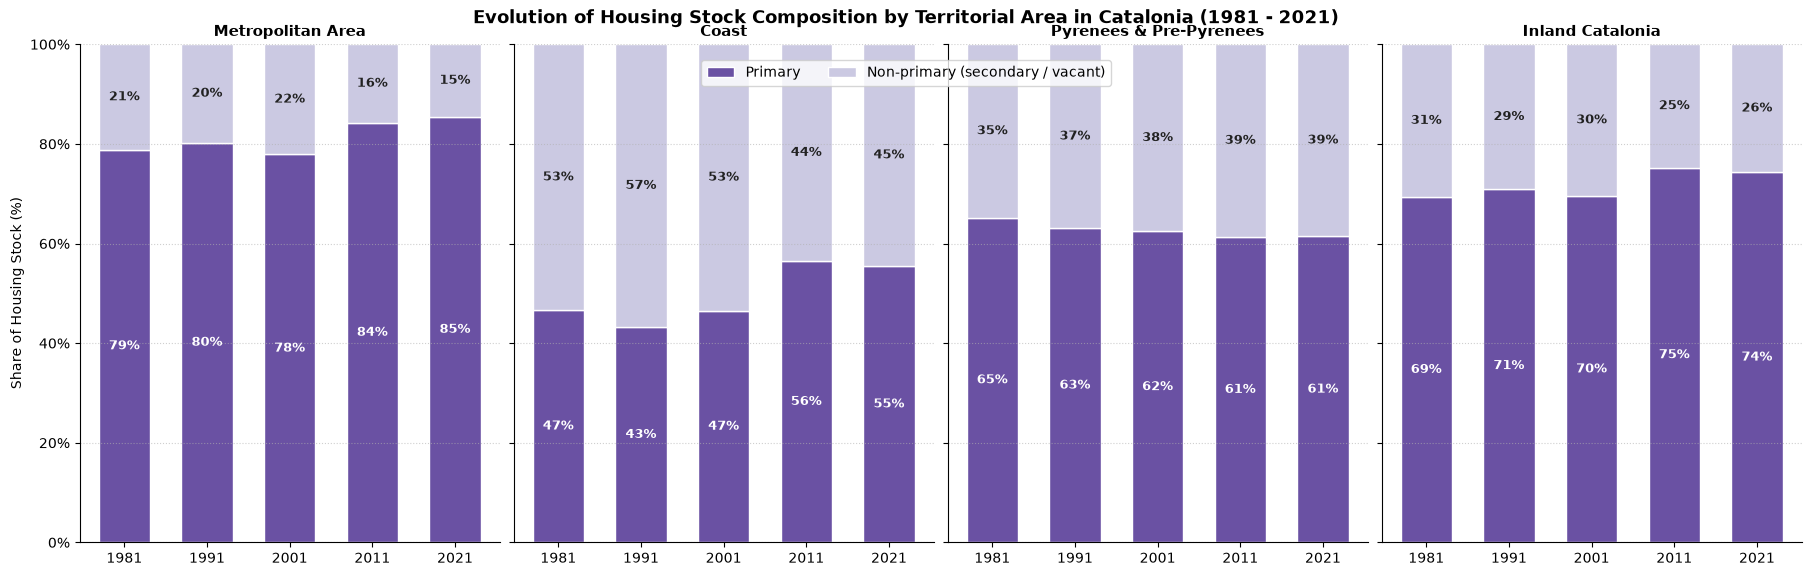

In [20]:
# Evolution of housing stock composition (% Primary vs. % Non-primary) by territorial area (1981 - 2021)

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

# 1. Load municipal geographic layer to assign each municipality to its territorial area based on county code
municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)
municipis["CODICOMAR"] = municipis["CODICOMAR"].astype(str).str.zfill(2)

# Classification of Idescat/ICGC county codes into 4 major territorial areas
comarques_amb = {"13", "11", "40", "41", "21", "17", "03"}  # Barcelonès, Baix Llobregat, Vallès Occ./Or., Maresme, Garraf, Alt Penedès
comarques_litoral = {"02", "10", "34", "36", "08", "12", "09", "22"}  # Costa Brava, Costa Daurada, and coastal Terres de l'Ebre
comarques_pirineu = {"04", "05", "15", "25", "26", "31", "39", "07", "35"}  # Alt Pirineu, Aran, Ripollès, Berguedà, and Solsonès

def assignar_ambit(codi_comarca):
    if codi_comarca in comarques_amb:
        return "Metropolitan Area"
    elif codi_comarca in comarques_litoral:
        return "Coast"
    elif codi_comarca in comarques_pirineu:
        return "Pyrenees & Pre-Pyrenees"
    else:
        return "Inland Catalonia"

municipis["Ambit"] = municipis["CODICOMAR"].apply(assignar_ambit)
mapa_ambits = municipis[["CODIMUNI", "Ambit"]].drop_duplicates()

# 2. Configuration of the 5 decennial housing census files
arxius_config = {
    1981: ("habitatges1981.csv", 4, "Total"),
    1991: ("habitatges1991.csv", 5, "Habitatges familiars. Total"),
    2001: ("habitatges2001.csv", 5, "Habitatges familiars    total"),
    2011: ("habitatges2011.csv", 6, "Habitatges familiars    total"),
    2021: ("habitatges2021.csv", 5, "Total habitatges familiars"),
}

# 3. Read all 5 census years, group by territorial area, and compute percentages
registres = []

for any_obj, (nom_arxiu, skip, col_total) in arxius_config.items():
    ruta_csv = f"../Data/BuildingsAvailable/{nom_arxiu}"
    df_hab = pd.read_csv(ruta_csv, sep=";", skiprows=skip, dtype={"Codi": str})
    df_hab = df_hab.dropna(subset=["Codi"]).copy()
    df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)

    # Automatically detect the primary dwellings column (excluding 'no principals')
    cols_principals = [c for c in df_hab.columns if "princip" in c.lower() and "no " not in c.lower()]
    col_principal = cols_principals[0]

    df_hab["Total"] = pd.to_numeric(df_hab[col_total], errors="coerce")
    df_hab["Principals"] = pd.to_numeric(df_hab[col_principal], errors="coerce")
    df_hab["No_principals"] = df_hab["Total"] - df_hab["Principals"]

    # Merge with territorial area and sum total dwellings per region
    df_zona = df_hab.merge(mapa_ambits, left_on="Codi", right_on="CODIMUNI", how="inner")
    resum = df_zona.groupby("Ambit", as_index=False)[["Total", "Principals", "No_principals"]].sum()
    resum["Any"] = str(any_obj)
    resum["Pct_principals"] = (resum["Principals"] / resum["Total"]) * 100
    resum["Pct_no_principals"] = (resum["No_principals"] / resum["Total"]) * 100
    registres.append(resum)

df_final = pd.concat(registres, ignore_index=True)

# 4. Plot 100% stacked bar chart (1 row x 4 territorial areas)
ambits_ordre = ["Metropolitan Area", "Coast", "Pyrenees & Pre-Pyrenees", "Inland Catalonia"]
fig, axes = plt.subplots(1, 4, figsize=(18, 5.5), sharey=True, layout="constrained")

color_principal = "#6a51a3"      # Dark purple for primary dwellings
color_no_principal = "#cbc9e2"   # Light lilac for non-primary dwellings (secondary / vacant)

for ax, ambit in zip(axes, ambits_ordre):
    sub = df_final[df_final["Ambit"] == ambit].sort_values("Any")

    # Bottom bar: % Primary
    barres_p = ax.bar(sub["Any"], sub["Pct_principals"], color=color_principal, edgecolor="white", width=0.62, label="Primary")
    # Top bar: % Non-primary (stacked on top of Primary)
    barres_np = ax.bar(
        sub["Any"],
        sub["Pct_no_principals"],
        bottom=sub["Pct_principals"],
        color=color_no_principal,
        edgecolor="white",
        width=0.62,
        label="Non-primary (secondary / vacant)",
    )

    # Write exact percentage inside each bar segment
    for b_p, b_np in zip(barres_p, barres_np):
        alt_p = b_p.get_height()
        alt_np = b_np.get_height()
        x_centre = b_p.get_x() + b_p.get_width() / 2

        if alt_p >= 8:
            ax.text(x_centre, alt_p / 2, f"{alt_p:.0f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
        if alt_np >= 8:
            ax.text(x_centre, alt_p + alt_np / 2, f"{alt_np:.0f}%", ha="center", va="center", color="#222222", fontweight="bold", fontsize=9)

    ax.set_title(ambit, fontweight="bold", fontsize=11)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(ticker.PercentFormatter())
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Share of Housing Stock (%)", fontsize=10)

# Single shared legend at the top
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=2, frameon=True, fontsize=10)

fig.suptitle("Evolution of Housing Stock Composition by Territorial Area in Catalonia (1981 - 2021)", fontweight="bold", fontsize=13, y=1.02)
plt.show()

## 7. Relationship Between Population Size and Dwellings per Inhabitant (2021)
This double-logarithmic (*log-log*) scatter plot compares the total population of each municipality with its dwellings-per-inhabitant ratio in 2021. Two reference lines (`0.5` and `1.0` dwellings per inhabitant) are included, and representative municipalities are labeled to contrast major metropolitan cities with coastal and mountain tourist destinations.

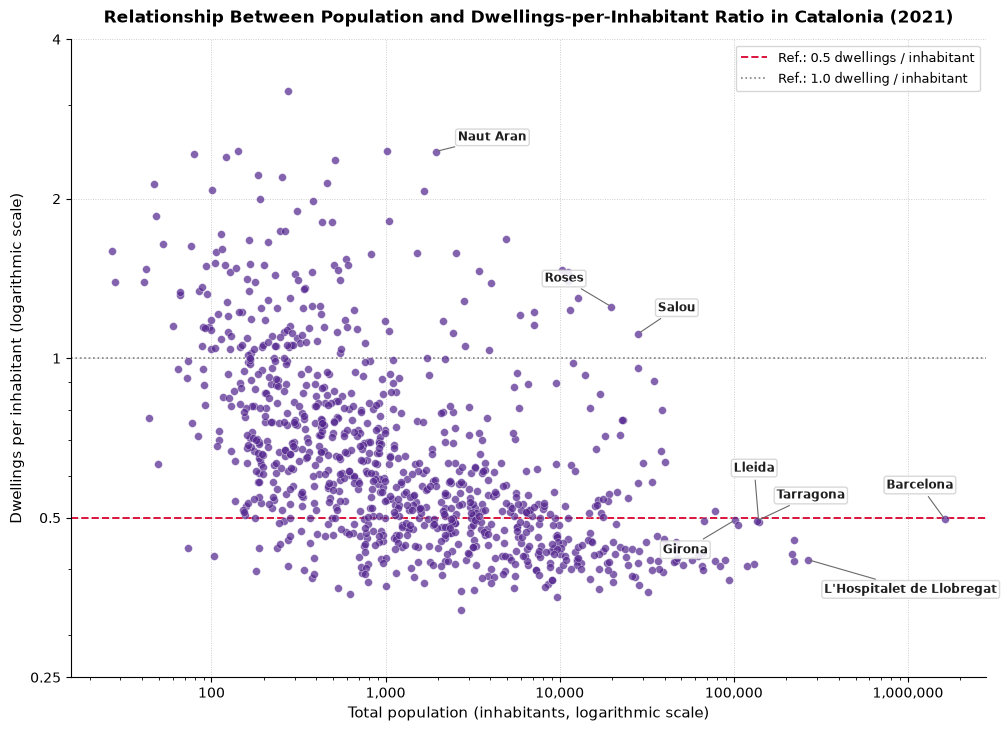

In [21]:
# Relationship between population and dwellings-per-inhabitant ratio in Catalonia (2021)

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Load municipal geographic layer of Catalonia
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convert municipal code to 6-digit zero-padded string (e.g., '080193')

# Load and clean population data ('Dades' sheet from poblacio_codis.xlsx)
ruta_pob = "../Data/BuildingsAvailable/poblacio_codis.xlsx"
df_pob = pd.read_excel(ruta_pob, sheet_name="Dades", skiprows=1, dtype={0: str}) 
df_pob = df_pob.rename(columns={df_pob.columns[0]: "Codi", df_pob.columns[1]: "Any"})  # Rename first two columns
df_pob["Codi"] = df_pob["Codi"].ffill().str.strip().str.zfill(6)  # Forward-fill municipal code and ensure 6 digits
df_pob = df_pob[df_pob["Codi"].str.match(r"^\d{6}$")].copy()  # Keep only valid 6-digit numeric codes (drops 'TOTAL' and footer notes)
df_pob["Any"] = df_pob["Any"].astype(int)  # Convert year to integer
df_pob["Poblacio"] = pd.to_numeric(df_pob["Total"], errors="coerce")  # Convert total population to numeric

# Read and prepare 2021 housing data
ruta_hab = "../Data/BuildingsAvailable/habitatges2021.csv"
df_hab = pd.read_csv(ruta_hab, sep=";", skiprows=5, dtype={"Codi": str})
df_hab = df_hab.dropna(subset=["Codi"]).copy()        # Remove rows without a municipal code
df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)   # Strip whitespace and ensure 6-digit municipal codes
df_hab["Total"] = pd.to_numeric(df_hab["Total habitatges familiars"], errors="coerce")   # Convert housing column to numeric (invalid strings become NaN)

# Filter 2021 population, merge with dwellings and municipality name, and compute ratio
pob_2021 = df_pob[df_pob["Any"] == 2021][["Codi", "Poblacio"]]
df = (
    df_hab[["Codi", "Total"]]
    .merge(pob_2021, on="Codi", how="inner")
    .merge(municipis[["CODIMUNI", "NOMMUNI"]], left_on="Codi", right_on="CODIMUNI", how="inner")
    .dropna()
)
df = df[(df["Poblacio"] > 0) & (df["Total"] > 0)].copy()  # Remove non-positive values to apply logarithmic scales
df["Hab_per_hab"] = df["Total"] / df["Poblacio"]

fig, ax = plt.subplots(figsize=(10, 7.2), layout="constrained")

# Plot scatter chart (Population vs. Ratio)
ax.scatter(
    df["Poblacio"],
    df["Hab_per_hab"],
    color="#54278f",
    s=32,
    alpha=0.72,
    edgecolors="white",
    linewidth=0.3,
    zorder=3,
)

# Horizontal reference lines
ax.axhline(0.5, color="crimson", linestyle="--", linewidth=1.4, zorder=2, label="Ref.: 0.5 dwellings / inhabitant")
ax.axhline(1.0, color="grey", linestyle=":", linewidth=1.2, zorder=2, label="Ref.: 1.0 dwelling / inhabitant")

# List of municipalities to label: (search_pattern, display_label, x_offset, y_offset)
etiquetes_destacades = [
    (r"^Barcelona$", "Barcelona", -42, 22),
    (r"Hospitalet de Llobregat", "L'Hospitalet de Llobregat", 12, -24),
    (r"^Lleida$", "Lleida", -18, 36),
    (r"^Tarragona$", "Tarragona", 14, 16),
    (r"^Girona$", "Girona", -52, -24),
    (r"^Salou$", "Salou", 14, 16),
    (r"^Roses$", "Roses", -48, 18),
    (r"^Naut Aran$", "Naut Aran", 16, 8),
]

# Iterate through the list and annotate each highlighted municipality
for patro, etiqueta, dx, dy in etiquetes_destacades:
    fila = df[df["NOMMUNI"].str.contains(patro, case=False, regex=True)]
    if not fila.empty:
        r = fila.iloc[0]
        ax.annotate(
            etiqueta,
            xy=(r["Poblacio"], r["Hab_per_hab"]),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=8.5,
            fontweight="bold",
            color="#1f1f1f",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="lightgrey", alpha=0.88),
            arrowprops=dict(arrowstyle="-", color="dimgray", lw=0.8),
            zorder=4,
        )

# Configure logarithmic scales on both axes
ax.set_xscale("log")
ax.set_yscale("log")

# Format axis numbers without scientific notation
fmt_enter = ticker.FuncFormatter(lambda x, _: f"{int(x):,}")
fmt_decimal = ticker.FuncFormatter(lambda x, _: f"{x:g}")

ax.xaxis.set_major_formatter(fmt_enter)
ax.set_yticks([0.25, 0.5, 1, 2, 4])
ax.yaxis.set_major_formatter(fmt_decimal)
ax.yaxis.set_minor_formatter(ticker.NullFormatter())

ax.grid(True, which="major", linestyle=":", linewidth=0.65, alpha=0.7, zorder=1)  # Add subtle background grid
ax.spines["top"].set_visible(False)  # Hide top frame spine
ax.spines["right"].set_visible(False)  # Hide right frame spine
ax.legend(loc="upper right", frameon=True, fontsize=9.5)  # Add reference line legend

ax.set_xlabel("Total population (inhabitants, logarithmic scale)", fontsize=10.5)
ax.set_ylabel("Dwellings per inhabitant (logarithmic scale)", fontsize=10.5)
ax.set_title(
    "Relationship Between Population and Dwellings-per-Inhabitant Ratio in Catalonia (2021)",
    fontweight="bold",
    fontsize=12.5,
    pad=12,
)

plt.show()